In [10]:
import json
import duckdb
import pandas as pd
import time

con = duckdb.connect()
con.execute("SET TimeZone = 'UTC'")

PATH = "../data/flows.parquet"
con.execute(f"CREATE OR REPLACE VIEW flows AS SELECT * FROM read_parquet('{PATH}')")

splits = json.load(open("../data/splits.json"))
TRAIN_END = splits["train_end_inclusive"]
VAL_END   = splits["validation_end_inclusive"]

con.execute(f'''
    CREATE OR REPLACE VIEW flows_clean AS
    SELECT
        *,
        CAST(flow_start AS TIMESTAMPTZ) AS t_start,
        CASE
            WHEN CAST(flow_start AS TIMESTAMPTZ) <= TIMESTAMPTZ '{TRAIN_END}' THEN 'train'
            WHEN CAST(flow_start AS TIMESTAMPTZ) <= TIMESTAMPTZ '{VAL_END}'   THEN 'val'
            ELSE 'test'
        END AS split
    FROM flows
    WHERE start_rtt > 0 AND end_rtt > 0
''')

con.sql("SELECT split, COUNT(*) AS n FROM flows_clean GROUP BY split ORDER BY split").df()

,split,n
0,test,10086352
1,train,46730686
2,val,10069254


In [11]:
schema = con.sql("DESCRIBE flows_clean").df()
schema[["column_name", "column_type"]]

,column_name,column_type
0,flow_id,VARCHAR
1,flow_start,VARCHAR
2,flow_end,VARCHAR
3,start_rtt,DOUBLE
4,end_rtt,DOUBLE
5,delta_rtt,DOUBLE
6,meta.src_ip,VARCHAR
7,meta.dst_ip,VARCHAR
8,meta.src_port,BIGINT
9,meta.dst_port,BIGINT


## 1. Cardinality of Categorical Variables (Train)
For each of the 14 categorical variables, we calculate on the train split only:
- n_unique: number of distinct values (exact, COUNT(DISTINCT));
- n_null and pct_null: missing values (NULL).

Purpose: to classify variables by cardinality and choose the tokenization strategy:
- low → one token per value;
- medium → vocabulary with frequency threshold and RARE token;
- high → aggregation (IP prefixes, port ranges).

Statistics are calculated solely on the train set to prevent leakage into validation and test.

In [12]:
# 1. Colonne da NON considerare categoriche
escludi = {
    "flow_id", "flow_start", "flow_end", "t_start", "split",
    "start_rtt", "end_rtt", "delta_rtt",
    "endpoints_match", "endpoints_reversed", "start_fields_match",
}
tipi_continui = ("DOUBLE", "FLOAT", "REAL", "DECIMAL", "TIMESTAMP")

cat_cols = [
    c for c, t in zip(schema["column_name"], schema["column_type"])
    if c not in escludi and not t.startswith(tipi_continui)
]
print(len(cat_cols), cat_cols)

# 2. Query: per ogni colonna, numero di valori distinti e di NULL
sel = ["COUNT(*) AS n_righe"]
for c in cat_cols:
    sel.append(f'COUNT(DISTINCT "{c}") AS "{c}__nunique"')
    sel.append(f'COUNT(*) - COUNT("{c}") AS "{c}__null"')

query = f"""
SELECT {", ".join(sel)}
FROM flows_clean
WHERE split = 'train'
"""

# 3. Esecuzione: una sola passata sul train
t0 = time.time()
riga = con.sql(query).df().iloc[0]
print(f"Tempo: {time.time() - t0:.1f} s")

# 4. Da una riga larga a una tabella con una riga per variabile
n = riga["n_righe"]
card = pd.DataFrame({
    "n_unique": [riga[f"{c}__nunique"] for c in cat_cols],
    "n_null":   [riga[f"{c}__null"] for c in cat_cols],
}, index=cat_cols)
card["pct_null"] = (100 * card["n_null"] / n).round(2)
card = card.sort_values("n_unique")
card

14 ['meta.src_ip', 'meta.dst_ip', 'meta.src_port', 'meta.dst_port', 'meta.cric.src.name', 'meta.cric.dst.name', 'meta.cric.src.asn', 'meta.cric.dst.asn', 'meta.application', 'meta.experiment_name', 'meta.activity_id', 'meta.protocol', 'meta.ip_version', 'meta.syslog.hostname']


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Tempo: 3.8 s


,n_unique,n_null,pct_null
meta.protocol,1,0,0.00
meta.ip_version,2,0,0.00
meta.experiment_name,6,0,0.00
meta.activity_id,22,0,0.00
meta.cric.dst.asn,58,1939839,4.15
meta.cric.src.asn,63,9165321,19.61
meta.cric.dst.name,77,1939839,4.15
meta.cric.src.name,89,9165321,19.61
meta.application,167,342283,0.73
meta.syslog.hostname,749,0,0.00


## 2. Variabili a bassa cardinalità

`meta.protocol`, `meta.ip_version`, `meta.experiment_name`, `meta.activity_id`.
Distribuzione delle frequenze sul train, per decidere se ogni valore riceve una propria categoria.
Controlli aggiuntivi:
- `meta.protocol` su tutti gli split (costante sul train);
- coppie esperimento × attività (gli ID di attività Scitags sono definiti per esperimento).

In [14]:
def freq(col, where="split = 'train'"):
    """Frequenza assoluta e percentuale di ogni valore di una colonna."""
    return con.sql(f'''
        SELECT
            "{col}" AS valore,
            COUNT(*) AS n,
            ROUND(100 * COUNT(*) / SUM(COUNT(*)) OVER (), 3) AS pct
        FROM flows_clean
        WHERE {where}
        GROUP BY "{col}"
        ORDER BY n DESC
    ''').df()

# 1. Frequenze sul train
for c in ["meta.ip_version", "meta.experiment_name", "meta.activity_id"]:
    print(c)
    display(freq(c))

# 2. Protocollo su tutti gli split
display(con.sql('''
    SELECT split, "meta.protocol" AS protocol, COUNT(*) AS n
    FROM flows_clean
    GROUP BY split, "meta.protocol"
    ORDER BY split
''').df())

# 3. Coppie esperimento × attività sul train
coppie = con.sql('''
    SELECT
        "meta.experiment_name" AS exp,
        "meta.activity_id"     AS act,
        COUNT(*) AS n,
        ROUND(100 * COUNT(*) / SUM(COUNT(*)) OVER (), 3) AS pct
    FROM flows_clean
    WHERE split = 'train'
    GROUP BY exp, act
    ORDER BY exp, n DESC
''').df()
print(f"Coppie distinte: {len(coppie)}")
display(coppie)

meta.ip_version


,valore,n,pct
0,6,35923966,76.874
1,4,10806720,23.126


meta.experiment_name


,valore,n,pct
0,cms,32216862,68.942
1,atlas,8067007,17.263
2,alice,6004535,12.849
3,unknown,245719,0.526
4,lhcb,140996,0.302
5,default,55567,0.119


meta.activity_id


,valore,n,pct
0,1,34001683,72.761
1,10,4486530,9.601
2,11,1537125,3.289
3,18,1244312,2.663
4,4,990197,2.119
5,12,891063,1.907
6,15,860501,1.841
7,9,644496,1.379
8,16,620636,1.328
9,17,455561,0.975


,split,protocol,n
0,test,tcp,10086352
1,train,tcp,46730686
2,val,tcp,10069254


Coppie distinte: 31


,exp,act,n,pct
0,alice,10,4473483,9.573
1,alice,12,885420,1.895
2,alice,9,644496,1.379
3,alice,13,1006,0.002
4,alice,15,130,0.000
5,atlas,1,2397093,5.130
6,atlas,11,1537125,3.289
7,atlas,18,1244312,2.663
8,atlas,15,860371,1.841
9,atlas,4,723448,1.548


## 3. Concentrazione top-k: `meta.application` e `meta.syslog.hostname`

Per ciascuna variabile, sul train:
- `k95`, `k99`: numero minimo di valori (dal più frequente) che coprono il 95% e il 99% delle righe;
- per alcune soglie candidate N (100, 1.000, 10.000 righe): numero di valori che superano la soglia
  e percentuale di righe coperte. Le righe restanti finirebbero nella categoria `RARE`.

I `NULL` sono trattati come un valore a sé (futura categoria `MISSING`).
Obiettivo: scegliere una soglia N unica per tutte le variabili categoriche.

,n_valori,k95,k99,valori n≥100,% righe n≥100,valori n≥1000,% righe n≥1000,valori n≥10000,% righe n≥10000
meta.application,168.0,10.0,19.0,97.0,99.996,57.0,99.959,34.0,99.810
meta.syslog.hostname,749.0,428.0,560.0,740.0,99.999,686.0,99.930,540.0,98.623


,valore,n,pct,cum_pct
0,cmsRun,22096929,47.286,47.285694
1,http-put,6237948,13.349,60.634413
2,JobWrapper,5509404,11.790,72.424105
3,unknown,4049059,8.665,81.088773
4,xrdcp,2127425,4.553,85.641296
5,MakeReducedNtuple_NANO.x,1745215,3.735,89.375919
6,python3.12,1004533,2.150,91.525541
7,python3,862878,1.846,93.372032
8,xrootd,611237,1.308,94.680031
9,python3.10,572530,1.225,95.905200


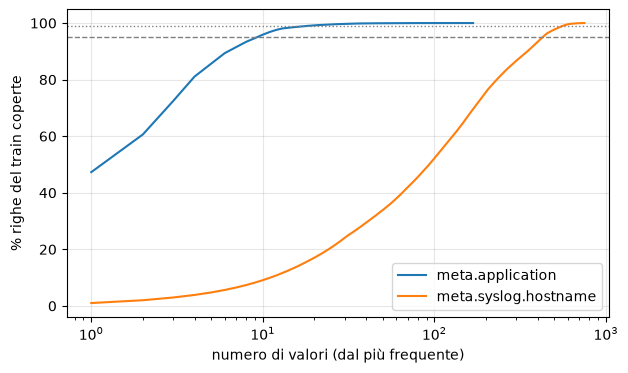

In [15]:
import matplotlib.pyplot as plt

def concentrazione(col, soglie=(100, 1_000, 10_000)):
    """Tabella delle frequenze con copertura cumulata + statistiche di sintesi."""
    f = freq(col)                                    # ordinata per n decrescente
    tot = f["n"].sum()
    f["cum_pct"] = 100 * f["n"].cumsum() / tot       # % di righe coperte dai primi k valori

    sintesi = {
        "n_valori": len(f),
        "k95": int((f["cum_pct"] < 95).sum()) + 1,
        "k99": int((f["cum_pct"] < 99).sum()) + 1,
    }
    for N in soglie:
        tenuti = f["n"] >= N
        sintesi[f"valori n≥{N}"] = int(tenuti.sum())
        sintesi[f"% righe n≥{N}"] = round(100 * f.loc[tenuti, "n"].sum() / tot, 3)
    return f, sintesi

tabelle, sintesi = {}, {}
for c in ["meta.application", "meta.syslog.hostname"]:
    tabelle[c], sintesi[c] = concentrazione(c)

display(pd.DataFrame(sintesi).T)
display(tabelle["meta.application"].head(20))

# Curva di copertura cumulata
fig, ax = plt.subplots(figsize=(7, 4))
for c, f in tabelle.items():
    ax.plot(range(1, len(f) + 1), f["cum_pct"], label=c)
ax.set_xscale("log")
ax.axhline(95, ls="--", c="grey", lw=1)
ax.axhline(99, ls=":",  c="grey", lw=1)
ax.set_xlabel("numero di valori (dal più frequente)")
ax.set_ylabel("% righe del train coperte")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## 4. Siti CRIC e ASN

Sul train:
- concentrazione top-k e soglia N = 1.000 per sito e ASN (sorgente e destinazione);
- relazione sito ↔ ASN (ASN per sito, siti per ASN), unendo i ruoli sorgente e destinazione;
- numero di siti distinti nell'unione sorgente ∪ destinazione (vocabolario condiviso o separato).

Su tutti gli split: percentuale di siti mancanti, per verificare la variazione nel tempo osservata sul train.

In [16]:
cric_cols = ["meta.cric.src.name", "meta.cric.dst.name",
             "meta.cric.src.asn",  "meta.cric.dst.asn"]

# 1. Concentrazione
risultati = {c: concentrazione(c) for c in cric_cols}
display(pd.DataFrame({c: r[1] for c, r in risultati.items()}).T)
display(risultati["meta.cric.src.name"][0].head(15))

# 2. Mancanti per split
display(con.sql('''
    SELECT
        split,
        ROUND(100 * AVG(CAST("meta.cric.src.name" IS NULL AS INTEGER)), 2) AS pct_src_mancante,
        ROUND(100 * AVG(CAST("meta.cric.dst.name" IS NULL AS INTEGER)), 2) AS pct_dst_mancante
    FROM flows_clean
    GROUP BY split
    ORDER BY split
''').df())

# 3. Relazione sito <-> ASN (sorgente e destinazione insieme)
sa = con.sql('''
    WITH coppie AS (
        SELECT "meta.cric.src.name" AS site, "meta.cric.src.asn" AS asn
        FROM flows_clean WHERE split = 'train'
        UNION ALL
        SELECT "meta.cric.dst.name", "meta.cric.dst.asn"
        FROM flows_clean WHERE split = 'train'
    )
    SELECT site, asn, COUNT(*) AS n
    FROM coppie
    WHERE site IS NOT NULL
    GROUP BY site, asn
''').df()

asn_per_sito = sa.groupby("site")["asn"].nunique()
siti_per_asn = sa.groupby("asn")["site"].nunique()

print("Siti distinti (src ∪ dst):", sa["site"].nunique())
print("ASN distinti (src ∪ dst): ", sa["asn"].nunique())
print("Siti con più di un ASN:   ", (asn_per_sito > 1).sum())
print("ASN condivisi da più siti:", (siti_per_asn > 1).sum())
display(siti_per_asn.sort_values(ascending=False).head(10))

,n_valori,k95,k99,valori n≥100,% righe n≥100,valori n≥1000,% righe n≥1000,valori n≥10000,% righe n≥10000
meta.cric.src.name,90.0,43.0,65.0,84.0,100.0,82.0,99.999,80.0,99.977
meta.cric.dst.name,78.0,9.0,29.0,76.0,100.0,70.0,99.996,48.0,99.744
meta.cric.src.asn,64.0,29.0,45.0,59.0,100.0,57.0,99.999,57.0,99.999
meta.cric.dst.asn,59.0,8.0,21.0,56.0,100.0,52.0,99.998,40.0,99.874


,valore,n,pct,cum_pct
0,NaN,9165321,19.613,19.613068
1,RAL-LCG2,4105330,8.785,28.398151
2,CERN-PROD,2558271,5.474,33.872651
3,FZK-LCG2,2202436,4.713,38.585691
4,INFN-LNL-2,2191268,4.689,43.274832
5,MIT_CMS,2114145,4.524,47.798937
6,INFN-TORINO,2106624,4.508,52.306947
7,IN2P3-CC,1965559,4.206,56.513089
8,INFN-T1,1896387,4.058,60.571208
9,JINR-T1,1641308,3.512,64.083478


,split,pct_src_mancante,pct_dst_mancante
0,test,13.42,3.27
1,train,19.61,4.15
2,val,17.85,4.06


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Siti distinti (src ∪ dst): 90
ASN distinti (src ∪ dst):  64
Siti con più di un ASN:    3
ASN condivisi da più siti: 13


asn
137     10
786      6
2614     3
2091     3
789      3
766      3
0        2
680      2
2875     2
2715     2
Name: site, dtype: int64

In [17]:
# Siti con ASN = 0
display(sa[sa["asn"] == 0])

# Siti con più di un ASN, e quanto pesa ciascun ASN
multi = asn_per_sito[asn_per_sito > 1].index
display(sa[sa["site"].isin(multi)].sort_values(["site", "n"], ascending=[True, False]))

,site,asn,n
10,GRIF,0,2117159
45,WEIZMANN-LCG2,0,5


,site,asn,n
50,AGLT2,237,186314
54,AGLT2,229,140
23,MWT2,160,187997
77,MWT2,10680,21749
14,SAMPA,1251,47971
6,SAMPA,28571,3


## 5. Prefissi IP

### 5a. Tabella di conversione IP → prefissi

Prefissi calcolati con il modulo `ipaddress` sugli IP unici (sorgente ∪ destinazione, tutti gli split),
a tre livelli di granularità:
- L1: /16 IPv4, /32 IPv6;
- L2 (default): /24 IPv4, /48 IPv6;
- L3: /24 IPv4, /64 IPv6.

Il prefisso è una funzione deterministica dell'IP e non stima parametri dai dati:
calcolarlo anche sugli IP di validation e test non introduce leakage.
Gli indirizzi IPv6 che incapsulano un IPv4 (`::ffff:a.b.c.d`) sono convertiti in IPv4.

In [18]:
import ipaddress

# 1. IP unici, sorgente e destinazione, tutti gli split
ips = con.sql('''
    SELECT "meta.src_ip" AS ip FROM flows_clean
    UNION
    SELECT "meta.dst_ip" FROM flows_clean
''').df()["ip"]
print("IP distinti (tutti gli split):", len(ips))

# 2. Livelli di prefisso: (lunghezza IPv4, lunghezza IPv6)
LIVELLI = {"L1": (16, 32), "L2": (24, 48), "L3": (24, 64)}

def prefissi(s):
    """Dato un IP come stringa, restituisce versione e prefisso a ogni livello."""
    try:
        ip = ipaddress.ip_address(s)
    except ValueError:                                   # stringa non valida
        return {"version": None, **{k: None for k in LIVELLI}}
    if ip.version == 6 and ip.ipv4_mapped is not None:   # ::ffff:a.b.c.d -> a.b.c.d
        ip = ip.ipv4_mapped
    out = {"version": ip.version}
    for k, (l4, l6) in LIVELLI.items():
        L = l4 if ip.version == 4 else l6
        out[k] = str(ipaddress.ip_network(f"{ip}/{L}", strict=False))
    return out

# 3. Tabella IP -> prefissi
ip_map = pd.DataFrame([prefissi(s) for s in ips])
ip_map.insert(0, "ip", ips.values)

print("IP non validi:", ip_map["version"].isna().sum())
print(ip_map["version"].value_counts())
display(ip_map.head())

# 4. Rendiamo la tabella interrogabile da DuckDB
con.register("ip_map", ip_map)

IP distinti (tutti gli split): 28643
IP non validi: 0
version
6    17011
4    11632
Name: count, dtype: int64


,ip,version,L1,L2,L3
0,2401:de00:2:33::112,6,2401:de00::/32,2401:de00:2::/48,2401:de00:2:33::/64
1,2001:660:3031:110:20::18,6,2001:660::/32,2001:660:3031::/48,2001:660:3031:110::/64
2,193.146.75.180,4,193.146.0.0/16,193.146.75.0/24,193.146.75.0/24
3,18.12.1.186,4,18.12.0.0/16,18.12.1.0/24,18.12.1.0/24
4,2001:6a8:1080::c:3612,6,2001:6a8::/32,2001:6a8:1080::/48,2001:6a8:1080::/64


### 5b. Cardinalità e concentrazione dei prefissi (train)

Per IP grezzo e per i livelli L1, L2, L3: numero di valori distinti come sorgente, come destinazione
e nell'unione (vocabolario condiviso), k95 e numero di valori con almeno N = 1.000 occorrenze.
Le occorrenze sono contate sui due ruoli insieme: ogni flow contribuisce due volte (sorgente e destinazione).

In [19]:
# 1. Occorrenze di ogni IP nel train, separate per ruolo
ip_counts = con.sql('''
    SELECT ip, ruolo, COUNT(*) AS n
    FROM (
        SELECT "meta.src_ip" AS ip, 'src' AS ruolo FROM flows_clean WHERE split = 'train'
        UNION ALL
        SELECT "meta.dst_ip",       'dst'          FROM flows_clean WHERE split = 'train'
    )
    GROUP BY ip, ruolo
''').df()

# 2. Attacchiamo i prefissi a ogni IP
c = ip_counts.merge(ip_map, on="ip", how="left")

# 3. Statistiche per livello
N = 1000
righe = []
for col in ["ip", "L1", "L2", "L3"]:
    per_valore = c.groupby(col)["n"].sum().sort_values(ascending=False)
    cum = 100 * per_valore.cumsum() / per_valore.sum()
    tenuti = per_valore >= N
    righe.append({
        "livello": col,
        "distinti src": c.loc[c["ruolo"] == "src", col].nunique(),
        "distinti dst": c.loc[c["ruolo"] == "dst", col].nunique(),
        "distinti src∪dst": len(per_valore),
        "k95": int((cum < 95).sum()) + 1,
        f"valori n≥{N}": int(tenuti.sum()),
        f"% occorrenze n≥{N}": round(100 * per_valore[tenuti].sum() / per_valore.sum(), 3),
    })

display(pd.DataFrame(righe).set_index("livello"))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,distinti src,distinti dst,distinti src∪dst,k95,valori n≥1000,% occorrenze n≥1000
livello,,,,,,
ip,25830,5088,27242,6895,7205,95.351
L1,268,242,357,50,160,99.978
L2,616,371,720,120,340,99.953
L3,832,497,959,243,526,99.942


### 5c. Tabella prefisso → sito e copertura dell'opzione B

Sul train, per ogni prefisso L2, distribuzione dei siti CRIC con cui compare (solo occorrenze con sito noto, ruoli sorgente e destinazione insieme):
- **purezza**: quota del sito più frequente;
- **supporto**: numero di occorrenze con sito noto.

Un prefisso è utilizzabile per l'imputazione se purezza ≥ 95% e supporto ≥ 100.
Per le occorrenze con sito mancante si misura la quota recuperabile, separata per ruolo.
La copertura su validation e test sarà misurata nel passo sulla sovrapposizione.

In [20]:
import numpy as np

# 1. Occorrenze (IP, ruolo, sito) nel train, sito mancante incluso
occ = con.sql('''
    SELECT ip, ruolo, site, COUNT(*) AS n
    FROM (
        SELECT "meta.src_ip" AS ip, 'src' AS ruolo, "meta.cric.src.name" AS site
        FROM flows_clean WHERE split = 'train'
        UNION ALL
        SELECT "meta.dst_ip", 'dst', "meta.cric.dst.name"
        FROM flows_clean WHERE split = 'train'
    )
    GROUP BY ip, ruolo, site
''').df()
occ = occ.merge(ip_map[["ip", "L2"]], on="ip", how="left")

# 2. Tabella prefisso -> sito (solo occorrenze con sito noto)
noti = occ[occ["site"].notna()]
ps = noti.groupby(["L2", "site"])["n"].sum().reset_index()
tab = (ps.sort_values("n", ascending=False)
         .groupby("L2")
         .agg(site_top=("site", "first"),
              n_top=("n", "first"),
              supporto=("n", "sum"),
              n_siti=("site", "nunique")))
tab["purezza"] = tab["n_top"] / tab["supporto"]

valida = tab[(tab["purezza"] >= 0.95) & (tab["supporto"] >= 100)]

print("Prefissi L2 con almeno un sito noto:     ", len(tab))
print("  con un solo sito (purezza 100%):       ", (tab["n_siti"] == 1).sum())
print("  validi per l'opzione B (≥95%, ≥100):   ", len(valida))

# 3. Esito per le occorrenze con sito mancante
m = occ[occ["site"].isna()].copy()
m["esito"] = np.select(
    [m["L2"].isin(valida.index), m["L2"].isin(tab.index)],
    ["recuperato", "prefisso ambiguo o poco supporto"],
    default="prefisso mai visto con sito",
)
esiti = m.groupby(["ruolo", "esito"])["n"].sum()
pct = (100 * esiti / esiti.groupby(level="ruolo").transform("sum")).round(2)
display(pd.DataFrame({"occorrenze": esiti, "pct del ruolo": pct}))

# 4. I prefissi ambigui più grandi
display(tab[tab["purezza"] < 0.95].sort_values("supporto", ascending=False).head(10))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Prefissi L2 con almeno un sito noto:      376
  con un solo sito (purezza 100%):        374
  validi per l'opzione B (≥95%, ≥100):    272


occorrenze  pct del ruolo
ruolo esito                                                      
dst   prefisso ambiguo o poco supporto          26           0.00
      prefisso mai visto con sito          1938299          99.92
      recuperato                              1514           0.08
src   prefisso ambiguo o poco supporto       82111           0.90
      prefisso mai visto con sito          7851944          85.67
      recuperato                           1231266          13.43

,site_top,n_top,supporto,n_siti,purezza
L2,,,,,
2001:638:700::/48,DESY-HH,461213,561518,2,0.821368


## 6. Porte

Sul train:
1. concentrazione top-k di porta di destinazione e porta sorgente (soglia N = 1.000);
2. istogramma per blocchi di 1.024 porte, con gli intervalli effimeri IANA (49152–65535) e Linux di default (32768–60999);
3. incrocio tra `endpoints_reversed` e il tipo di porta (bassa < 32768, effimera ≥ 32768) di sorgente e destinazione,
   per verificare se le porte di destinazione effimere provengono da flow registrati in verso invertito.

`endpoints_reversed` dipende dall'evento di fine ed è usato solo come variabile di analisi, non come input dei modelli.

,n_valori,k95,k99,valori n≥100,% righe n≥100,valori n≥1000,% righe n≥1000,valori n≥10000,% righe n≥10000
meta.dst_port,64408.0,10494.0,13952.0,14129.0,99.189,7.0,81.981,3.0,81.939
meta.src_port,64510.0,17841.0,34370.0,26818.0,97.810,14652.0,92.649,27.0,14.170


,valore,n,pct,cum_pct
0,1095,28968192,61.990,61.989657
1,1094,9303586,19.909,81.898601
2,1101,18948,0.041,81.939148
3,1102,9525,0.020,81.959531
4,1103,4891,0.010,81.969997
5,2880,4061,0.009,81.978687
6,8443,1008,0.002,81.980844
7,43130,667,0.001,81.982272
8,54434,658,0.001,81.983680
9,57616,658,0.001,81.985088


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

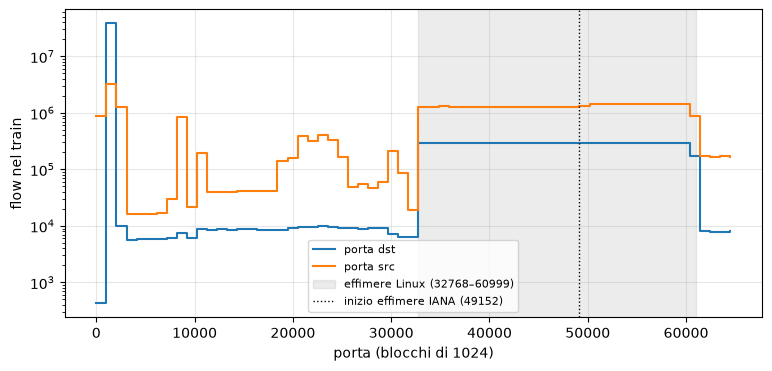

,endpoints_reversed,dst,src,n,pct del gruppo
0,False,bassa,bassa,401539,2.62
1,False,bassa,effimera,6761524,44.09
2,False,effimera,bassa,8050512,52.50
3,False,effimera,effimera,122082,0.80
4,True,bassa,bassa,803880,2.56
5,True,bassa,effimera,30587730,97.43
6,True,effimera,bassa,2925,0.01
7,True,effimera,effimera,494,0.00


In [21]:
# 1. Concentrazione
porte = {c: concentrazione(c) for c in ["meta.dst_port", "meta.src_port"]}
display(pd.DataFrame({c: r[1] for c, r in porte.items()}).T)
display(porte["meta.dst_port"][0].head(20))

# 2. Istogramma per blocchi di 1024 porte
h = con.sql('''
    SELECT 'dst' AS ruolo, "meta.dst_port" // 1024 AS blocco, COUNT(*) AS n
    FROM flows_clean WHERE split = 'train' GROUP BY 1, 2
    UNION ALL
    SELECT 'src', "meta.src_port" // 1024, COUNT(*)
    FROM flows_clean WHERE split = 'train' GROUP BY 1, 2
''').df()

fig, ax = plt.subplots(figsize=(9, 4))
for ruolo, g in h.groupby("ruolo"):
    g = g.sort_values("blocco")
    ax.step(g["blocco"] * 1024, g["n"], where="post", label=f"porta {ruolo}")
ax.axvspan(32768, 61000, color="grey", alpha=0.15, label="effimere Linux (32768–60999)")
ax.axvline(49152, color="black", ls=":", lw=1, label="inizio effimere IANA (49152)")
ax.set_yscale("log")
ax.set_xlabel("porta (blocchi di 1024)")
ax.set_ylabel("flow nel train")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.show()

# 3. Tipo di porta vs endpoints_reversed
x = con.sql('''
    SELECT
        endpoints_reversed,
        CASE WHEN "meta.dst_port" < 32768 THEN 'bassa' ELSE 'effimera' END AS dst,
        CASE WHEN "meta.src_port" < 32768 THEN 'bassa' ELSE 'effimera' END AS src,
        COUNT(*) AS n
    FROM flows_clean
    WHERE split = 'train'
    GROUP BY ALL
    ORDER BY ALL
''').df()
x["pct del gruppo"] = (100 * x["n"] / x.groupby("endpoints_reversed")["n"].transform("sum")).round(2)
display(x)

In [22]:
con.sql('''
    SELECT "meta.dst_port" AS dst, "meta.src_port" AS src, COUNT(*) AS n
    FROM flows_clean
    WHERE split = 'train'
      AND "meta.dst_port" < 32768 AND "meta.src_port" < 32768
    GROUP BY ALL
    ORDER BY n DESC
    LIMIT 15
''').df()

,dst,src,n
0,1094,22200,59
1,1094,18660,57
2,1095,17712,56
3,1095,28318,56
4,1094,19682,56
5,1094,12620,56
6,1094,24044,56
7,1094,22898,56
8,1094,23048,56
9,1094,14878,55


### 6b. Regola di orientamento (servizio / client)

Porte di servizio note: porte di destinazione con almeno N = 1.000 flow nel train.
Regola a cascata:
1. `dst_port` è una porta di servizio nota → servizio in destinazione;
2. `src_port` è una porta di servizio nota → servizio in sorgente;
3. una sola porta < 32768 → quella è il servizio;
4. altrimenti la porta più bassa, con orientamento marcato come incerto.

Si misura la quota di flow del train decisa da ciascun passo.

In [29]:
# Porte di servizio note: porte di destinazione con almeno N flow nel train
PORTE_SERVIZIO = porte["meta.dst_port"][0].query("n >= 1000")["valore"].astype(int).tolist()
print("Porte di servizio:", PORTE_SERVIZIO)
lista = ", ".join(map(str, PORTE_SERVIZIO))

regole = con.sql(f'''
    WITH p AS (
        SELECT "meta.src_port" AS sp, "meta.dst_port" AS dp
        FROM flows_clean
        WHERE split = 'train'
    )
    SELECT
        CASE
            WHEN dp IN ({lista})                THEN '1. dst = servizio noto'
            WHEN sp IN ({lista})                THEN '2. src = servizio noto'
            WHEN dp < 32768 AND sp >= 32768     THEN '3a. solo dst bassa'
            WHEN sp < 32768 AND dp >= 32768     THEN '3b. solo src bassa'
            ELSE                                     '4. incerto (porta più bassa)'
        END AS regola,
        COUNT(*) AS n,
        ROUND(100 * COUNT(*) / SUM(COUNT(*)) OVER (), 3) AS pct
    FROM p
    GROUP BY regola
    ORDER BY regola
''').df()
display(regole)

Porte di servizio: [1095, 1094, 1101, 1102, 1103, 2880, 8443]


,regola,n,pct
0,1. dst = servizio noto,38310211,81.981
1,2. src = servizio noto,4788830,10.248
2,3a. solo dst bassa,8600,0.018
3,3b. solo src bassa,3420040,7.319
4,4. incerto (porta più bassa),203005,0.434


In [30]:
caso_3b = f'''
    FROM flows_clean
    WHERE split = 'train'
      AND "meta.dst_port" NOT IN ({lista})
      AND "meta.src_port" NOT IN ({lista})
      AND "meta.src_port" < 32768
      AND "meta.dst_port" >= 32768
'''

print(con.sql(f'SELECT COUNT(DISTINCT "meta.src_port") AS porte_src_distinte {caso_3b}').df())

display(con.sql(f'''
    SELECT
        "meta.src_port" AS src,
        COUNT(*) AS n,
        ROUND(100 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct_del_caso
    {caso_3b}
    GROUP BY src
    ORDER BY n DESC
    LIMIT 15
''').df())

   porte_src_distinte
0                9575


,src,n,pct_del_caso
0,443,876172,25.62
1,8446,233444,6.83
2,2881,112869,3.30
3,18443,98013,2.87
4,11000,96596,2.82
5,9000,52985,1.55
6,11001,52792,1.54
7,9001,40507,1.18
8,2882,38077,1.11
9,23174,18854,0.55


In [31]:
# Porte basse con almeno N flow nel train, in qualsiasi ruolo
cand = con.sql('''
    SELECT porta, SUM(n) AS n
    FROM (
        SELECT "meta.dst_port" AS porta, COUNT(*) AS n
        FROM flows_clean WHERE split = 'train' GROUP BY 1
        UNION ALL
        SELECT "meta.src_port", COUNT(*)
        FROM flows_clean WHERE split = 'train' GROUP BY 1
    )
    WHERE porta < 32768
    GROUP BY porta
    HAVING SUM(n) >= 1000
    ORDER BY n DESC
''').df()

PORTE_SERVIZIO = cand["porta"].astype(int).tolist()
lista = ", ".join(map(str, PORTE_SERVIZIO))
print("Porte di servizio:", len(PORTE_SERVIZIO))
display(cand.head(25))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Porte di servizio: 537


,porta,n
0,1095,29214070.0
1,1094,12246429.0
2,2880,1114186.0
3,443,895582.0
4,8443,491067.0
5,8446,237327.0
6,2881,114763.0
7,18443,99885.0
8,11000,98887.0
9,9000,55150.0


In [32]:
cand["blocco"] = (cand["porta"] // 1000) * 1000
blocchi = (cand.groupby("blocco")
               .agg(n_porte=("porta", "size"),
                    flow=("n", "sum"),
                    flow_medi_per_porta=("n", "median")))
blocchi["pct_flow"] = (100 * blocchi["flow"] / cand["n"].sum()).round(2)
display(blocchi)

,n_porte,flow,flow_medi_per_porta,pct_flow
blocco,,,,
0,1,895582.0,895582.0,1.95
1000,5,41493905.0,18957.0,90.50
2000,4,1269614.0,76732.5,2.77
8000,4,743000.0,125222.5,1.62
9000,2,97181.0,48590.5,0.21
11000,2,151900.0,75950.0,0.33
18000,1,99885.0,99885.0,0.22
20000,94,195039.0,1455.5,0.43
21000,90,158118.0,1388.0,0.34


In [35]:
regole = con.sql(f'''
    WITH p AS (
        SELECT "meta.src_port" AS sp, "meta.dst_port" AS dp
        FROM flows_clean
        WHERE split = 'train'
    )
    SELECT
        CASE
            WHEN dp IN ({lista})                THEN '1. dst = servizio noto'
            WHEN sp IN ({lista})                THEN '2. src = servizio noto'
            WHEN dp < 32768 AND sp >= 32768     THEN '3a. solo dst bassa'
            WHEN sp < 32768 AND dp >= 32768     THEN '3b. solo src bassa'
            ELSE                                     '4. incerto (porta più bassa)'
        END AS regola,
        COUNT(*) AS n,
        ROUND(100 * COUNT(*) / SUM(COUNT(*)) OVER (), 3) AS pct
    FROM p
    GROUP BY regola
    ORDER BY regola
''').df()
display(regole)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,regola,n,pct
0,1. dst = servizio noto,38317048,81.995
1,2. src = servizio noto,7508866,16.068
2,3a. solo dst bassa,6231,0.013
3,3b. solo src bassa,749625,1.604
4,4. incerto (porta più bassa),148916,0.319


In [34]:
# Intervallo 20000-24999: limiti effettivi
r = cand[(cand["porta"] >= 20000) & (cand["porta"] < 25000)]["porta"]
print("Intervallo 20000-24999:", r.min(), "-", r.max(), "|", len(r), "porte candidate")

# Blocco 30000 nel dettaglio
display(cand[cand["blocco"] == 30000].sort_values("porta"))

Intervallo 20000-24999: 20000 - 24991 | 463 porte candidate


,porta,n,blocco
419,30029,1115.0,30000
370,30035,1199.0,30000
38,30050,8217.0,30000
498,30051,1039.0,30000
511,30078,1024.0,30000
237,30086,1556.0,30000
508,30122,1027.0,30000
41,30123,8150.0,30000
16,30162,16408.0,30000
43,30163,8085.0,30000


In [36]:
# Porte nominate = candidate fuori dagli intervalli
in_range = cand["porta"].between(20000, 24999) | cand["porta"].between(30000, 30999)
NOMINATE = cand.loc[~in_range, "porta"].astype(int).tolist()
print("Porte nominate:", len(NOMINATE))
lista_nom = ", ".join(map(str, NOMINATE))

# Una "funzione" SQL riutilizzabile: vero se la porta è di servizio
con.execute(f'''
    CREATE OR REPLACE MACRO servizio(x) AS
        x IN ({lista_nom})
        OR x BETWEEN 20000 AND 24999
        OR x BETWEEN 30000 AND 30999
''')

regole = con.sql('''
    WITH p AS (
        SELECT "meta.src_port" AS sp, "meta.dst_port" AS dp
        FROM flows_clean WHERE split = 'train'
    )
    SELECT
        CASE
            WHEN servizio(dp)                THEN '1. dst = servizio'
            WHEN servizio(sp)                THEN '2. src = servizio'
            WHEN dp < 32768 AND sp >= 32768  THEN '3a. solo dst bassa'
            WHEN sp < 32768 AND dp >= 32768  THEN '3b. solo src bassa'
            ELSE                                  '4. incerto (porta più bassa)'
        END AS regola,
        COUNT(*) AS n,
        ROUND(100 * COUNT(*) / SUM(COUNT(*)) OVER (), 3) AS pct
    FROM p
    GROUP BY regola
    ORDER BY regola
''').df()
display(regole)

Porte nominate: 42


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,regola,n,pct
0,1. dst = servizio,38365703,82.100
1,2. src = servizio,8199163,17.546
2,3a. solo dst bassa,2668,0.006
3,3b. solo src bassa,38761,0.083
4,4. incerto (porta più bassa),124391,0.266


## 7. Sovrapposizione train / validation / test

### 7a. Vista con le colonne trasformate e tassi RARE / UNK

Vista `flows_x`: `flows_clean` con prefissi L2 di sorgente e destinazione, coppia esperimento × attività
e porta di servizio (regola a cascata del passo 6). Sarà riusata per il salvataggio finale.

Per ogni variabile, vocabolario = valori con almeno N = 1.000 occorrenze nel train.
Per ogni split: % di occorrenze nel vocabolario, in `RARE` (visto nel train, sotto soglia),
in `UNK` (mai visto nel train) e mancanti. Siti e prefissi usano un vocabolario condiviso tra sorgente e destinazione.

In [37]:
# 1. Vista con le colonne trasformate
con.execute('''
    CREATE OR REPLACE VIEW flows_x AS
    SELECT
        f.*,
        ms.L2 AS src_L2,
        md.L2 AS dst_L2,
        f."meta.experiment_name" || '_' || CAST(f."meta.activity_id" AS VARCHAR) AS exp_act,
        CASE
            WHEN servizio(f."meta.dst_port") THEN f."meta.dst_port"
            WHEN servizio(f."meta.src_port") THEN f."meta.src_port"
            WHEN f."meta.dst_port" < 32768 AND f."meta.src_port" >= 32768 THEN f."meta.dst_port"
            WHEN f."meta.src_port" < 32768 AND f."meta.dst_port" >= 32768 THEN f."meta.src_port"
            ELSE least(f."meta.src_port", f."meta.dst_port")
        END AS porta_servizio
    FROM flows_clean AS f
    LEFT JOIN ip_map AS ms ON f."meta.src_ip" = ms.ip
    LEFT JOIN ip_map AS md ON f."meta.dst_ip" = md.ip
''')

# 2. Funzione di sovrapposizione
def sovrapposizione(nome, espressioni, N=1000):
    """Tassi vocabolario / RARE / UNK / mancante per split.
    espressioni: una o più colonne (più di una = vocabolario condiviso tra ruoli)."""
    union = " UNION ALL ".join(f"SELECT split, {e} AS v FROM flows_x" for e in espressioni)
    q = f'''
        WITH occ AS ({union}),
             voc AS (SELECT v, COUNT(*) AS n_train FROM occ WHERE split = 'train' GROUP BY v)
        SELECT
            occ.split,
            ROUND(100 * AVG(CASE WHEN occ.v IS NULL                         THEN 1 ELSE 0 END), 3) AS pct_mancante,
            ROUND(100 * AVG(CASE WHEN voc.n_train >= {N}                     THEN 1 ELSE 0 END), 3) AS pct_vocab,
            ROUND(100 * AVG(CASE WHEN voc.n_train <  {N}                     THEN 1 ELSE 0 END), 3) AS pct_rare,
            ROUND(100 * AVG(CASE WHEN occ.v IS NOT NULL AND voc.v IS NULL    THEN 1 ELSE 0 END), 3) AS pct_unk
        FROM occ
        LEFT JOIN voc ON occ.v = voc.v
        GROUP BY occ.split
        ORDER BY occ.split
    '''
    df = con.sql(q).df()
    df.insert(0, "variabile", nome)
    return df

# 3. Tabella per tutte le variabili
variabili = {
    "application":       ['"meta.application"'],
    "hostname":          ['"meta.syslog.hostname"'],
    "exp_act":           ['exp_act'],
    "sito (src ∪ dst)":  ['"meta.cric.src.name"', '"meta.cric.dst.name"'],
    "prefisso L2 (src ∪ dst)": ['src_L2', 'dst_L2'],
    "porta_servizio":    ['porta_servizio'],
}

t0 = time.time()
sov = pd.concat([sovrapposizione(k, v) for k, v in variabili.items()], ignore_index=True)
print(f"Tempo: {time.time() - t0:.0f} s")
display(sov.set_index(["variabile", "split"]))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Tempo: 40 s


pct_mancante  pct_vocab  pct_rare  pct_unk
variabile               split                                            
application             test          0.894     98.368     0.128    0.610
                        train         0.732     99.226     0.041    0.000
                        val           0.427     99.479     0.058    0.037
hostname                test          0.000     99.639     0.055    0.306
                        train         0.000     99.930     0.070    0.000
                        val           0.000     99.597     0.092    0.311
exp_act                 test          0.000     99.999     0.001    0.000
                        train         0.000    100.000     0.000    0.000
                        val           0.000     99.584     0.416    0.000
sito (src ∪ dst)        test          8.348     91.641     0.012    0.000
                        train        11.882     88.117     0.001    0.000
                        val          10.956     89.042     0.002    0.000
prefisso L2 (src ∪ dst) test          0.000     99.909     0.084    0.007
                        train         0.000     99.953     0.047    0.000
                        val           0.000     99.847     0.142    0.011
porta_servizio          test          0.000     97.731     2.245    0.025
                        train         0.000     97.893     2.107    0.000
                        val           0.000     97.106     2.865    0.030

### 7b. Porta di servizio codificata, orientamento e coppie esperimento × attività rare, per split

- distribuzione della porta di servizio per tipo di categoria (porta nominata, intervallo, fascia);
- quota di flow per orientamento (client → server, server → client, incerto);
- coppie esperimento × attività con meno di N = 1.000 righe nel train, e loro frequenza negli altri split.

In [38]:
# 1. Codifica finale della porta di servizio
con.execute(f'''
    CREATE OR REPLACE MACRO porta_cat(p) AS
        CASE
            WHEN p BETWEEN 20000 AND 24999 THEN 'RANGE_20000'
            WHEN p BETWEEN 30000 AND 30999 THEN 'RANGE_30000'
            WHEN p IN ({lista_nom})         THEN CAST(p AS VARCHAR)
            WHEN p < 1024                   THEN 'WELL_KNOWN'
            WHEN p < 32768                  THEN 'REGISTERED'
            WHEN p <= 60999                 THEN 'EPHEMERAL'
            ELSE                                 'HIGH'
        END
''')

tipo = con.sql('''
    SELECT
        split,
        CASE
            WHEN porta_cat(porta_servizio) LIKE 'RANGE%' THEN 'intervallo'
            WHEN porta_cat(porta_servizio) IN ('WELL_KNOWN', 'REGISTERED', 'EPHEMERAL', 'HIGH') THEN 'fascia'
            ELSE 'porta nominata'
        END AS tipo,
        COUNT(*) AS n
    FROM flows_x
    GROUP BY ALL
''').df()
tipo["pct"] = (100 * tipo["n"] / tipo.groupby("split")["n"].transform("sum")).round(3)
display(tipo.pivot(index="tipo", columns="split", values="pct"))

# 2. Orientamento per split
verso = con.sql('''
    SELECT
        split,
        CASE
            WHEN servizio("meta.dst_port") THEN 'client → server'
            WHEN servizio("meta.src_port") THEN 'server → client'
            WHEN "meta.dst_port" < 32768 AND "meta.src_port" >= 32768 THEN 'client → server'
            WHEN "meta.src_port" < 32768 AND "meta.dst_port" >= 32768 THEN 'server → client'
            ELSE 'incerto'
        END AS verso,
        COUNT(*) AS n
    FROM flows_x
    GROUP BY ALL
''').df()
verso["pct"] = (100 * verso["n"] / verso.groupby("split")["n"].transform("sum")).round(3)
display(verso.pivot(index="verso", columns="split", values="pct"))

# 3. Coppie esperimento x attività rare nel train
display(con.sql('''
    WITH t AS (
        SELECT exp_act, COUNT(*) AS n_train
        FROM flows_x WHERE split = 'train'
        GROUP BY exp_act
    )
    SELECT f.exp_act, t.n_train, f.split, COUNT(*) AS n
    FROM flows_x AS f
    JOIN t USING (exp_act)
    WHERE t.n_train < 1000
    GROUP BY ALL
    ORDER BY ALL
''').df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

split,test,train,val
tipo,,,
fascia,0.318,0.355,0.453
intervallo,4.015,3.876,5.053
porta nominata,95.668,95.769,94.494


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

split,test,train,val
verso,,,
client → server,83.613,82.105,80.360
incerto,0.234,0.266,0.324
server → client,16.153,17.629,19.315


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,exp_act,n_train,split,n
0,alice_15,130,test,34
1,alice_15,130,train,130
2,alice_15,130,val,19
3,lhcb_4,18,test,18
4,lhcb_4,18,train,18
5,lhcb_4,18,val,41889


### 7c. Valori nuovi di `application` e origine del calo dei siti mancanti

- valori di `application` in validation/test fuori dal vocabolario del train (RARE o UNK), con il loro conteggio nel train;
- per il sito sorgente, per split: quota di flow in reti senza sito (prefissi L2 mai associati a un sito nel train),
  quota di sito mancante, e quota di sito mancante dentro reti con sito noto.

In [39]:
# 1. Application fuori dal vocabolario in val/test
display(con.sql('''
    WITH voc AS (
        SELECT "meta.application" AS v, COUNT(*) AS n_train
        FROM flows_x WHERE split = 'train'
        GROUP BY 1
    )
    SELECT f.split, f."meta.application" AS app, voc.n_train, COUNT(*) AS n
    FROM flows_x AS f
    LEFT JOIN voc ON f."meta.application" = voc.v
    WHERE f.split <> 'train'
      AND f."meta.application" IS NOT NULL
      AND (voc.v IS NULL OR voc.n_train < 1000)
    GROUP BY ALL
    ORDER BY n DESC
    LIMIT 20
''').df())

# 2. Siti sorgente mancanti: cambio di mix o miglioramento di CRIC?
con.register("pfx_con_sito", pd.DataFrame({"L2": tab.index}))
display(con.sql('''
    SELECT
        f.split,
        ROUND(100 * AVG(CASE WHEN p.L2 IS NULL THEN 1 ELSE 0 END), 2) AS pct_flow_reti_senza_sito,
        ROUND(100 * AVG(CASE WHEN f."meta.cric.src.name" IS NULL THEN 1 ELSE 0 END), 2) AS pct_sito_mancante,
        ROUND(100 * AVG(CASE WHEN f."meta.cric.src.name" IS NULL AND p.L2 IS NOT NULL THEN 1 ELSE 0 END), 2)
            AS pct_mancante_in_reti_note
    FROM flows_x AS f
    LEFT JOIN pfx_con_sito AS p ON f.src_L2 = p.L2
    GROUP BY f.split
    ORDER BY f.split
''').df())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,split,app,n_train,n
0,test,convert_branch_d5516f540f0b,<NA>,29199
1,test,convert_branch_27734b35541e,<NA>,29113
2,test,cmsrun3,12,8303
3,val,NonPrompt_MCprompt.exe,556,2549
4,test,ucache,560,1616
5,val,vbfhmm_config_run3_WCR_v5_24_nohehf_data_2024,<NA>,1490
6,test,VBS.exe,742,1227
7,test,dump_tracks_nano,<NA>,1150
8,test,vbfhmm_config_run3_SRSB_v5_24_nohehf_mc_2024,<NA>,977
9,val,vhmm_config_data_2024,<NA>,729


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,split,pct_flow_reti_senza_sito,pct_sito_mancante,pct_mancante_in_reti_note
0,test,11.52,13.42,1.91
1,train,16.80,19.61,2.81
2,val,15.90,17.85,1.95


## 8. Salvataggio di `flows_prepared.parquet`

### 8a. Costruzione e scrittura

Una riga per flow (`flows_clean`), con colonne leggibili per tutte le rappresentazioni:
- identificativi, tempo, split; target `delta_rtt`; input numerico `start_rtt`;
- colonne con prefisso `an_`: solo per analisi, **mai come input** (dipendono dall'evento di fine);
- categoriche: `ip_version`, `experiment`, `exp_act`, `application`, `hostname`;
- siti, ASN e prefissi L1/L2/L3 per sorgente e destinazione; mancanti e ASN 0 → `"MISSING"`;
- porte grezze, porta di servizio codificata, fascia della porta client, orientamento (`C2S` / `S2C`) e flag di incertezza;
- colonne canoniche `server_*` / `client_*`, costruite con l'orientamento.

Nessuna soglia `RARE`/`UNK` è applicata: i vocabolari sono costruiti nello stadio successivo.
Le scelte stimate dal train (porte di servizio, intervalli) sono salvate in `preparazione_config.json`.

In [41]:
OUT = "../data/flows_prepared.parquet"

# 1. Fascia della porta client
con.execute('''
    CREATE OR REPLACE MACRO porta_fascia(p) AS
        CASE
            WHEN p < 1024   THEN 'WELL_KNOWN'
            WHEN p < 32768  THEN 'REGISTERED'
            WHEN p <= 60999 THEN 'EPHEMERAL'
            ELSE                 'HIGH'
        END
''')

# 2. Colonne canoniche server_* / client_*, generate in Python
canoniche = []
for col in ["site", "asn", "L1", "L2", "L3"]:
    canoniche.append(f"CASE WHEN verso = 'C2S' THEN dst_{col} ELSE src_{col} END AS server_{col}")
    canoniche.append(f"CASE WHEN verso = 'C2S' THEN src_{col} ELSE dst_{col} END AS client_{col}")
canoniche_sql = ",\n        ".join(canoniche)

# 3. Vista finale
con.execute(f'''
    CREATE OR REPLACE VIEW flows_prepared AS
    WITH base AS (
        SELECT
            f.*,
            ms.L1 AS src_L1, ms.L2 AS src_L2, ms.L3 AS src_L3,
            md.L1 AS dst_L1, md.L2 AS dst_L2, md.L3 AS dst_L3,
            CASE
                WHEN servizio(f."meta.dst_port") THEN 'C2S'
                WHEN servizio(f."meta.src_port") THEN 'S2C'
                WHEN f."meta.dst_port" < 32768 AND f."meta.src_port" >= 32768 THEN 'C2S'
                WHEN f."meta.src_port" < 32768 AND f."meta.dst_port" >= 32768 THEN 'S2C'
                WHEN f."meta.dst_port" <= f."meta.src_port" THEN 'C2S'
                ELSE 'S2C'
            END AS verso,
            NOT (servizio(f."meta.dst_port")
                 OR servizio(f."meta.src_port")
                 OR (f."meta.dst_port" < 32768) <> (f."meta.src_port" < 32768)) AS verso_incerto
        FROM flows_clean AS f
        LEFT JOIN ip_map AS ms ON f."meta.src_ip" = ms.ip
        LEFT JOIN ip_map AS md ON f."meta.dst_ip" = md.ip
    ),
    pulito AS (
        SELECT
            flow_id, t_start, split,
            delta_rtt, start_rtt,
            end_rtt            AS an_end_rtt,
            endpoints_reversed AS an_endpoints_reversed,
            epoch(CAST(flow_end AS TIMESTAMPTZ)) - epoch(t_start) AS an_durata_s,
            "meta.ip_version"     AS ip_version,
            "meta.experiment_name" AS experiment,
            "meta.experiment_name" || '_' || CAST("meta.activity_id" AS VARCHAR) AS exp_act,
            COALESCE("meta.application", 'MISSING') AS application,
            "meta.syslog.hostname" AS hostname,
            COALESCE("meta.cric.src.name", 'MISSING') AS src_site,
            COALESCE("meta.cric.dst.name", 'MISSING') AS dst_site,
            CASE WHEN "meta.cric.src.asn" IS NULL OR "meta.cric.src.asn" = 0
                 THEN 'MISSING' ELSE CAST("meta.cric.src.asn" AS VARCHAR) END AS src_asn,
            CASE WHEN "meta.cric.dst.asn" IS NULL OR "meta.cric.dst.asn" = 0
                 THEN 'MISSING' ELSE CAST("meta.cric.dst.asn" AS VARCHAR) END AS dst_asn,
            src_L1, src_L2, src_L3, dst_L1, dst_L2, dst_L3,
            "meta.src_port" AS src_port,
            "meta.dst_port" AS dst_port,
            "meta.src_ip" AS src_ip, 
            "meta.dst_ip" AS dst_ip,
            verso, verso_incerto,
            CASE WHEN verso = 'C2S' THEN "meta.dst_port" ELSE "meta.src_port" END AS porta_servizio_num,
            CASE WHEN verso = 'C2S' THEN "meta.src_port" ELSE "meta.dst_port" END AS porta_client_num
        FROM base
    )
    SELECT
        * EXCLUDE (porta_servizio_num, porta_client_num),
        porta_cat(porta_servizio_num)   AS porta_servizio,
        porta_fascia(porta_client_num)  AS porta_client,
        {canoniche_sql}
    FROM pulito
''')

# 4. Scrittura su disco
t0 = time.time()
con.execute(f"COPY (SELECT * FROM flows_prepared) TO '{OUT}' (FORMAT PARQUET, COMPRESSION ZSTD)")
print(f"Scritto {OUT} in {time.time() - t0:.0f} s")

# 5. Configurazione stimata dal train, per la riproducibilità
config_prep = {
    "N_soglia": 1000,
    "porte_servizio_nominate": NOMINATE,
    "intervalli_porte_servizio": [[20000, 24999], [30000, 30999]],
    "intervallo_effimero_linux": [32768, 60999],
    "prefissi": {"L1": [16, 32], "L2": [24, 48], "L3": [24, 64]},
}
with open("../data/preparazione_config.json", "w") as fh:
    json.dump(config_prep, fh, indent=2)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Scritto ../data/flows_prepared.parquet in 39 s


### 8b. Verifica di `flows_prepared.parquet`

Rilettura del file scritto e controlli:
- righe per split (devono coincidere con `flows_clean`);
- tipo, numero approssimativo di valori distinti e percentuale di `NULL` per colonna;
- coerenza delle colonne canoniche con l'orientamento, quote di `S2C` e di orientamento incerto, durate negative;
- spazio occupato da ogni colonna nel file.

In [42]:
con.execute(f"CREATE OR REPLACE VIEW prep AS SELECT * FROM read_parquet('{OUT}')")

# 1. Righe per split
display(con.sql("SELECT split, COUNT(*) AS n FROM prep GROUP BY split ORDER BY split").df())

# 2. Riepilogo per colonna
t0 = time.time()
summ = con.sql("SUMMARIZE prep").df()
print(f"SUMMARIZE: {time.time() - t0:.0f} s")
display(summ[["column_name", "column_type", "approx_unique", "null_percentage"]])

# 3. Controlli di coerenza (train)
display(con.sql('''
    SELECT
        SUM(CASE WHEN verso = 'C2S' AND (server_L2 <> dst_L2 OR client_L2 <> src_L2) THEN 1 ELSE 0 END)
      + SUM(CASE WHEN verso = 'S2C' AND (server_L2 <> src_L2 OR client_L2 <> dst_L2) THEN 1 ELSE 0 END)
            AS errori_canoniche,
        ROUND(100 * AVG(CASE WHEN verso = 'S2C' THEN 1 ELSE 0 END), 3) AS pct_S2C,
        ROUND(100 * AVG(CAST(verso_incerto AS INTEGER)), 3)            AS pct_incerto,
        SUM(CASE WHEN an_durata_s < 0 THEN 1 ELSE 0 END)                AS durate_negative
    FROM prep
    WHERE split = 'train'
''').df())

# 4. Spazio occupato da ogni colonna
dim = con.sql(f'''
    SELECT path_in_schema AS colonna,
           ROUND(SUM(total_compressed_size) / 1e6, 1) AS MB
    FROM parquet_metadata('{OUT}')
    GROUP BY colonna
    ORDER BY MB DESC
''').df()
print(f"Totale: {dim['MB'].sum() / 1000:.2f} GB")
display(dim)

,split,n
0,test,10086352
1,train,46730686
2,val,10069254


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

SUMMARIZE: 17 s


,column_name,column_type,approx_unique,null_percentage
0,flow_id,VARCHAR,60784823,0.0
1,t_start,TIMESTAMP WITH TIME ZONE,68831331,0.0
2,split,VARCHAR,3,0.0
3,delta_rtt,DOUBLE,586671,0.0
4,start_rtt,DOUBLE,375270,0.0
5,an_end_rtt,DOUBLE,378678,0.0
6,an_endpoints_reversed,BOOLEAN,2,0.0
7,an_durata_s,DOUBLE,54950203,0.0
8,ip_version,BIGINT,2,0.0
9,experiment,VARCHAR,6,0.0


,errori_canoniche,pct_S2C,pct_incerto,durate_negative
0,0.0,17.773,0.266,0.0


Totale: 5.25 GB


,colonna,MB
0,flow_id,2368.5
1,an_durata_s,350.9
2,t_start,236.4
3,an_end_rtt,233.0
4,start_rtt,224.2
5,delta_rtt,217.4
6,src_ip,155.2
7,src_port,146.7
8,dst_ip,99.3
9,hostname,83.9
